Crop Disease Classification using Transfer Learning

This notebook trains a pretrained MobileNetV3-Small model on the PlantVillage dataset using 3-fold cross-validation and Guided Grad-CAM.

Importing Libraries

In [ ]:
from sklearn.model_selection import KFold
from torch.utils.data import Subset, DataLoader
from pytorch_grad_cam import GuidedBackpropReLUModel, GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import numpy as np
import cv2

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [24]:
source = "PlantVillage/PlantVillage"
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
dataset = datasets.ImageFolder(source, transform=transform)
num_classes = len(dataset.classes)
print(len(dataset))
print(num_classes)

20638
15


Adding K-fold setup cell

In [25]:
kf = KFold(n_splits=3, shuffle=True, random_state=42)

fold_results = []

Training the model


===== Fold 1 =====
Fold 1, Epoch 1, Loss: 333.2434
Fold 1, Epoch 2, Loss: 155.3983
Fold 1, Epoch 3, Loss: 124.2166
Fold 1, Epoch 4, Loss: 108.4636
Fold 1, Epoch 5, Loss: 96.2862
Fold 1, Epoch 6, Loss: 92.5237
Fold 1, Epoch 7, Loss: 85.5024
Fold 1, Epoch 8, Loss: 80.2349
Fold 1, Epoch 9, Loss: 75.5894
Fold 1, Epoch 10, Loss: 71.8712
Fold 1 Accuracy: 93.24%

===== Fold 2 =====
Fold 2, Epoch 1, Loss: 332.6403
Fold 2, Epoch 2, Loss: 154.9657
Fold 2, Epoch 3, Loss: 123.3820
Fold 2, Epoch 4, Loss: 107.8312
Fold 2, Epoch 5, Loss: 96.8317
Fold 2, Epoch 6, Loss: 89.0613
Fold 2, Epoch 7, Loss: 82.4074
Fold 2, Epoch 8, Loss: 79.1340
Fold 2, Epoch 9, Loss: 78.1254
Fold 2, Epoch 10, Loss: 74.5342
Fold 2 Accuracy: 92.92%

===== Fold 3 =====
Fold 3, Epoch 1, Loss: 338.8383
Fold 3, Epoch 2, Loss: 158.2917
Fold 3, Epoch 3, Loss: 125.9320
Fold 3, Epoch 4, Loss: 108.3334
Fold 3, Epoch 5, Loss: 97.5364
Fold 3, Epoch 6, Loss: 92.6781
Fold 3, Epoch 7, Loss: 86.6743
Fold 3, Epoch 8, Loss: 80.5667
Fold 3, Ep

<Figure size 1200x1200 with 0 Axes>

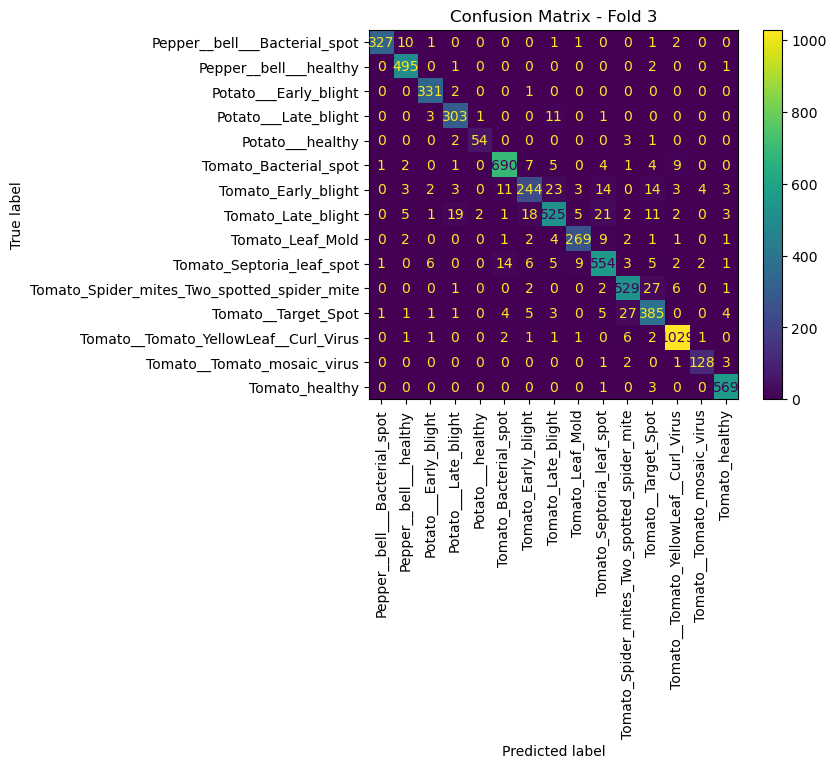

Fold 3 Accuracy: 93.50%


In [27]:
best_accuracy = 0
best_model = None
best_fold = None
for fold, (train_idx, val_idx) in enumerate(kf.split(dataset)):
    print(f"\n===== Fold {fold+1} =====")

    train_dataset = Subset(dataset, train_idx)
    val_dataset = Subset(dataset, val_idx)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    model = models.mobilenet_v3_small(weights="DEFAULT")

    for param in model.parameters(): #FREEZING THE BACKBONE
        param.requires_grad = False

    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes) #LOADING THE MODEL

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.classifier[3].parameters(), lr=0.001)

    epochs = 10

    for epoch in range(epochs):  #SET NUMBER OF EPOCHS ON EACH FOLD
        model.train()
        running_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
        
        print(f"Fold {fold+1}, Epoch {epoch+1}, Loss: {running_loss:.4f}")

    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0

    with torch.no_grad(): #VALIDATION LOOP
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    fold_results.append(accuracy)

    if fold == 2:  #CONFUSION MATRIX
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(12,12))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=dataset.classes)
        disp.plot(xticks_rotation=90)
        plt.title(f"Confusion Matrix - Fold {fold+1}")
        plt.savefig("results/confusion_matrix.png", bbox_inches="tight")
        plt.show()

    print(f"Fold {fold+1} Accuracy: {accuracy:.2f}%")

    torch.save(model.state_dict(), f"mobilenet_fold_{fold+1}.pth")

    if fold == 0 or accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model
        best_fold = fold + 1

        torch.save(model.state_dict(), "best_model.pth")

        sample_images = images
        sample_labels = labels

Mean Accuracy Cell

In [28]:
print("Fold Accuracies:", fold_results)
print("Mean Accuracy:", np.mean(fold_results))
print("Std Dev:", np.std(fold_results))
print("Best Fold:", best_fold)
print("Best Accuracy:", best_accuracy)

Fold Accuracies: [93.24127906976744, 92.920482628289, 93.50196249454862]
Mean Accuracy: 93.22124139753502
Std Dev: 0.23781062486454652
Best Fold: 3
Best Accuracy: 93.50196249454862


Guided Grad-Cam

In [ ]:
image_tensor = sample_images[0].unsqueeze(0).to(device)
label = sample_labels[0].item()

best_model.eval()

Enabling Gradients

In [40]:
for param in best_model.features[12].parameters():
    param.requires_grad = True

Last Convolutional Layer

In [41]:
target_layers = [best_model.features[12][0]]

cam = GradCAM(model=best_model, target_layers=target_layers)

targets = [ClassifierOutputTarget(label)]

gray_cam = cam(input_tensor=image_tensor, targets=targets)[0]

Guided Backprop Image

In [ ]:
gb_model = GuidedBackpropReLUModel(model=best_model, device=device)
gb = gb_model(image_tensor, target_category=label)

gb = cv2.normalize(gb, None, 0, 1, cv2.NORM_MINMAX)

Combining Both

In [65]:
rgb_img = image_tensor[0].detach().cpu().permute(1,2,0).numpy()

rgb_img = (rgb_img * 0.5) + 0.5
rgb_img = np.clip(rgb_img, 0, 1)

cam_image = show_cam_on_image(rgb_img, gray_cam, use_rgb=True)

guided_gradcam = cam_image * gb
guided_gradcam = cv2.normalize(guided_gradcam, None, 0, 255, cv2.NORM_MINMAX)
guided_gradcam = guided_gradcam.astype(np.uint8)

In [52]:
print(rgb_img.shape)
print(gb.shape)

(224, 224, 3)
(224, 224, 3)


Guided Grad Cam Output

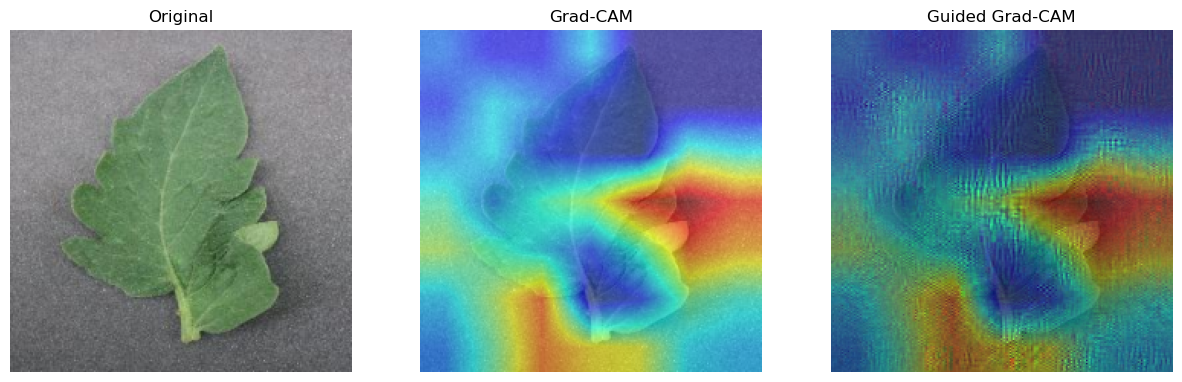

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(rgb_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(cam_image)
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(guided_gradcam)
plt.title("Guided Grad-CAM")
plt.axis("off")

plt.savefig("results/guided_gradcam.png", bbox_inches="tight")
plt.show()

Sample Prediction Cell

Actual: Pepper__bell___Bacterial_spot
Predicted: Pepper__bell___Bacterial_spot


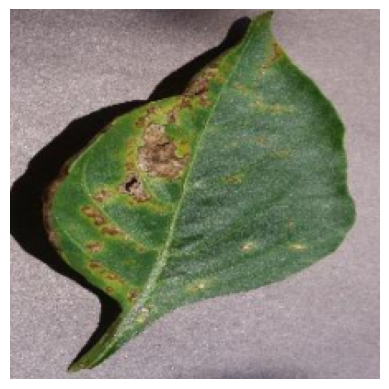

In [59]:
best_model.eval()

image, label = dataset[0]

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = best_model(input_tensor)
    predicted_class = torch.argmax(output, dim=1).item()

display_img = image.permute(1,2,0).cpu().numpy()
display_img = (display_img * 0.5) + 0.5
display_img = display_img.clip(0, 1)

plt.imshow(display_img)
plt.axis("off")

plt.savefig("results/sample_prediction.png", bbox_inches="tight")
print("Actual:", dataset.classes[label])
print("Predicted:", dataset.classes[predicted_class])